# Lasso and Ridge Regression

## A Note from sklearn on the Boston Dataset

* A message about the deprecation of the Boston dataset: [sklearn changelist](https://scikit-learn.org/stable/whats_new/v1.0.html#id9)
* The deprecation message in sklearn from v1.1: [sklearn.datasets.load_boston](https://scikit-learn.org/1.1/modules/generated/sklearn.datasets.load_boston.html)
* The Boston dataset in the sklearn v1.1 userguide: [sklearn user guide](https://scikit-learn.org/1.1/datasets/toy_dataset.html#boston-dataset)


<Axes: >

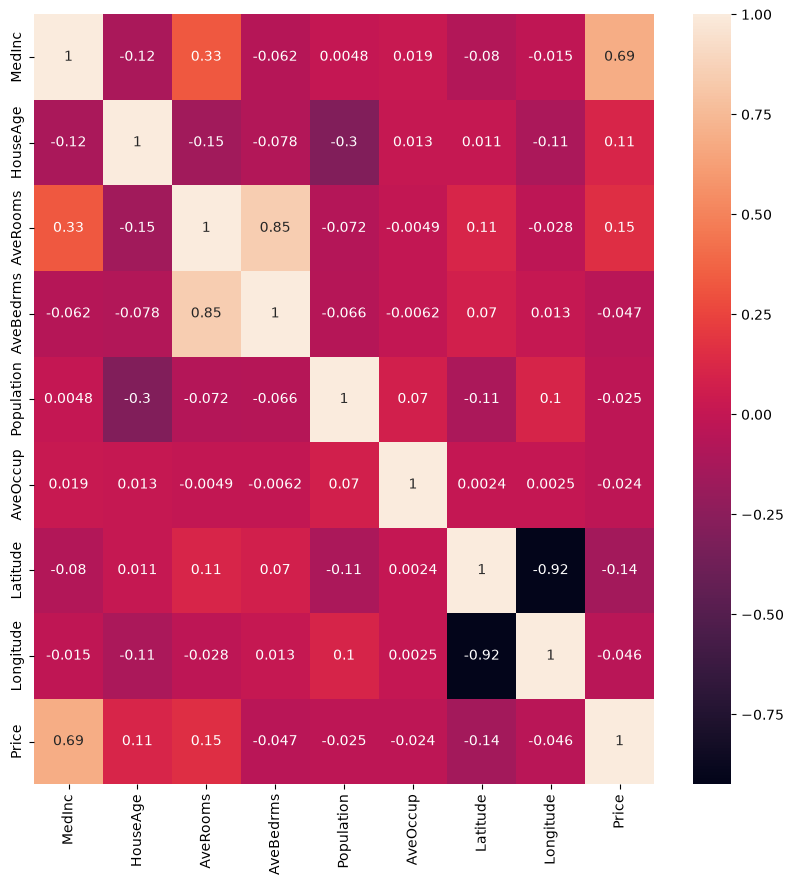

In [312]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

housing_fetched = fetch_california_housing(data_home="../scikit_learn_data", return_X_y=True, as_frame=True, download_if_missing=False)
data, target = housing_fetched

#data = pd.DataFrame(data, columns=housing_fetched.feature_names)
data = pd.DataFrame(data)

#target variable
data['Price']=target
#preview
data.head()

#Exploration
plt.figure(figsize = (10, 10))
sns.heatmap(data.corr(), annot = True)

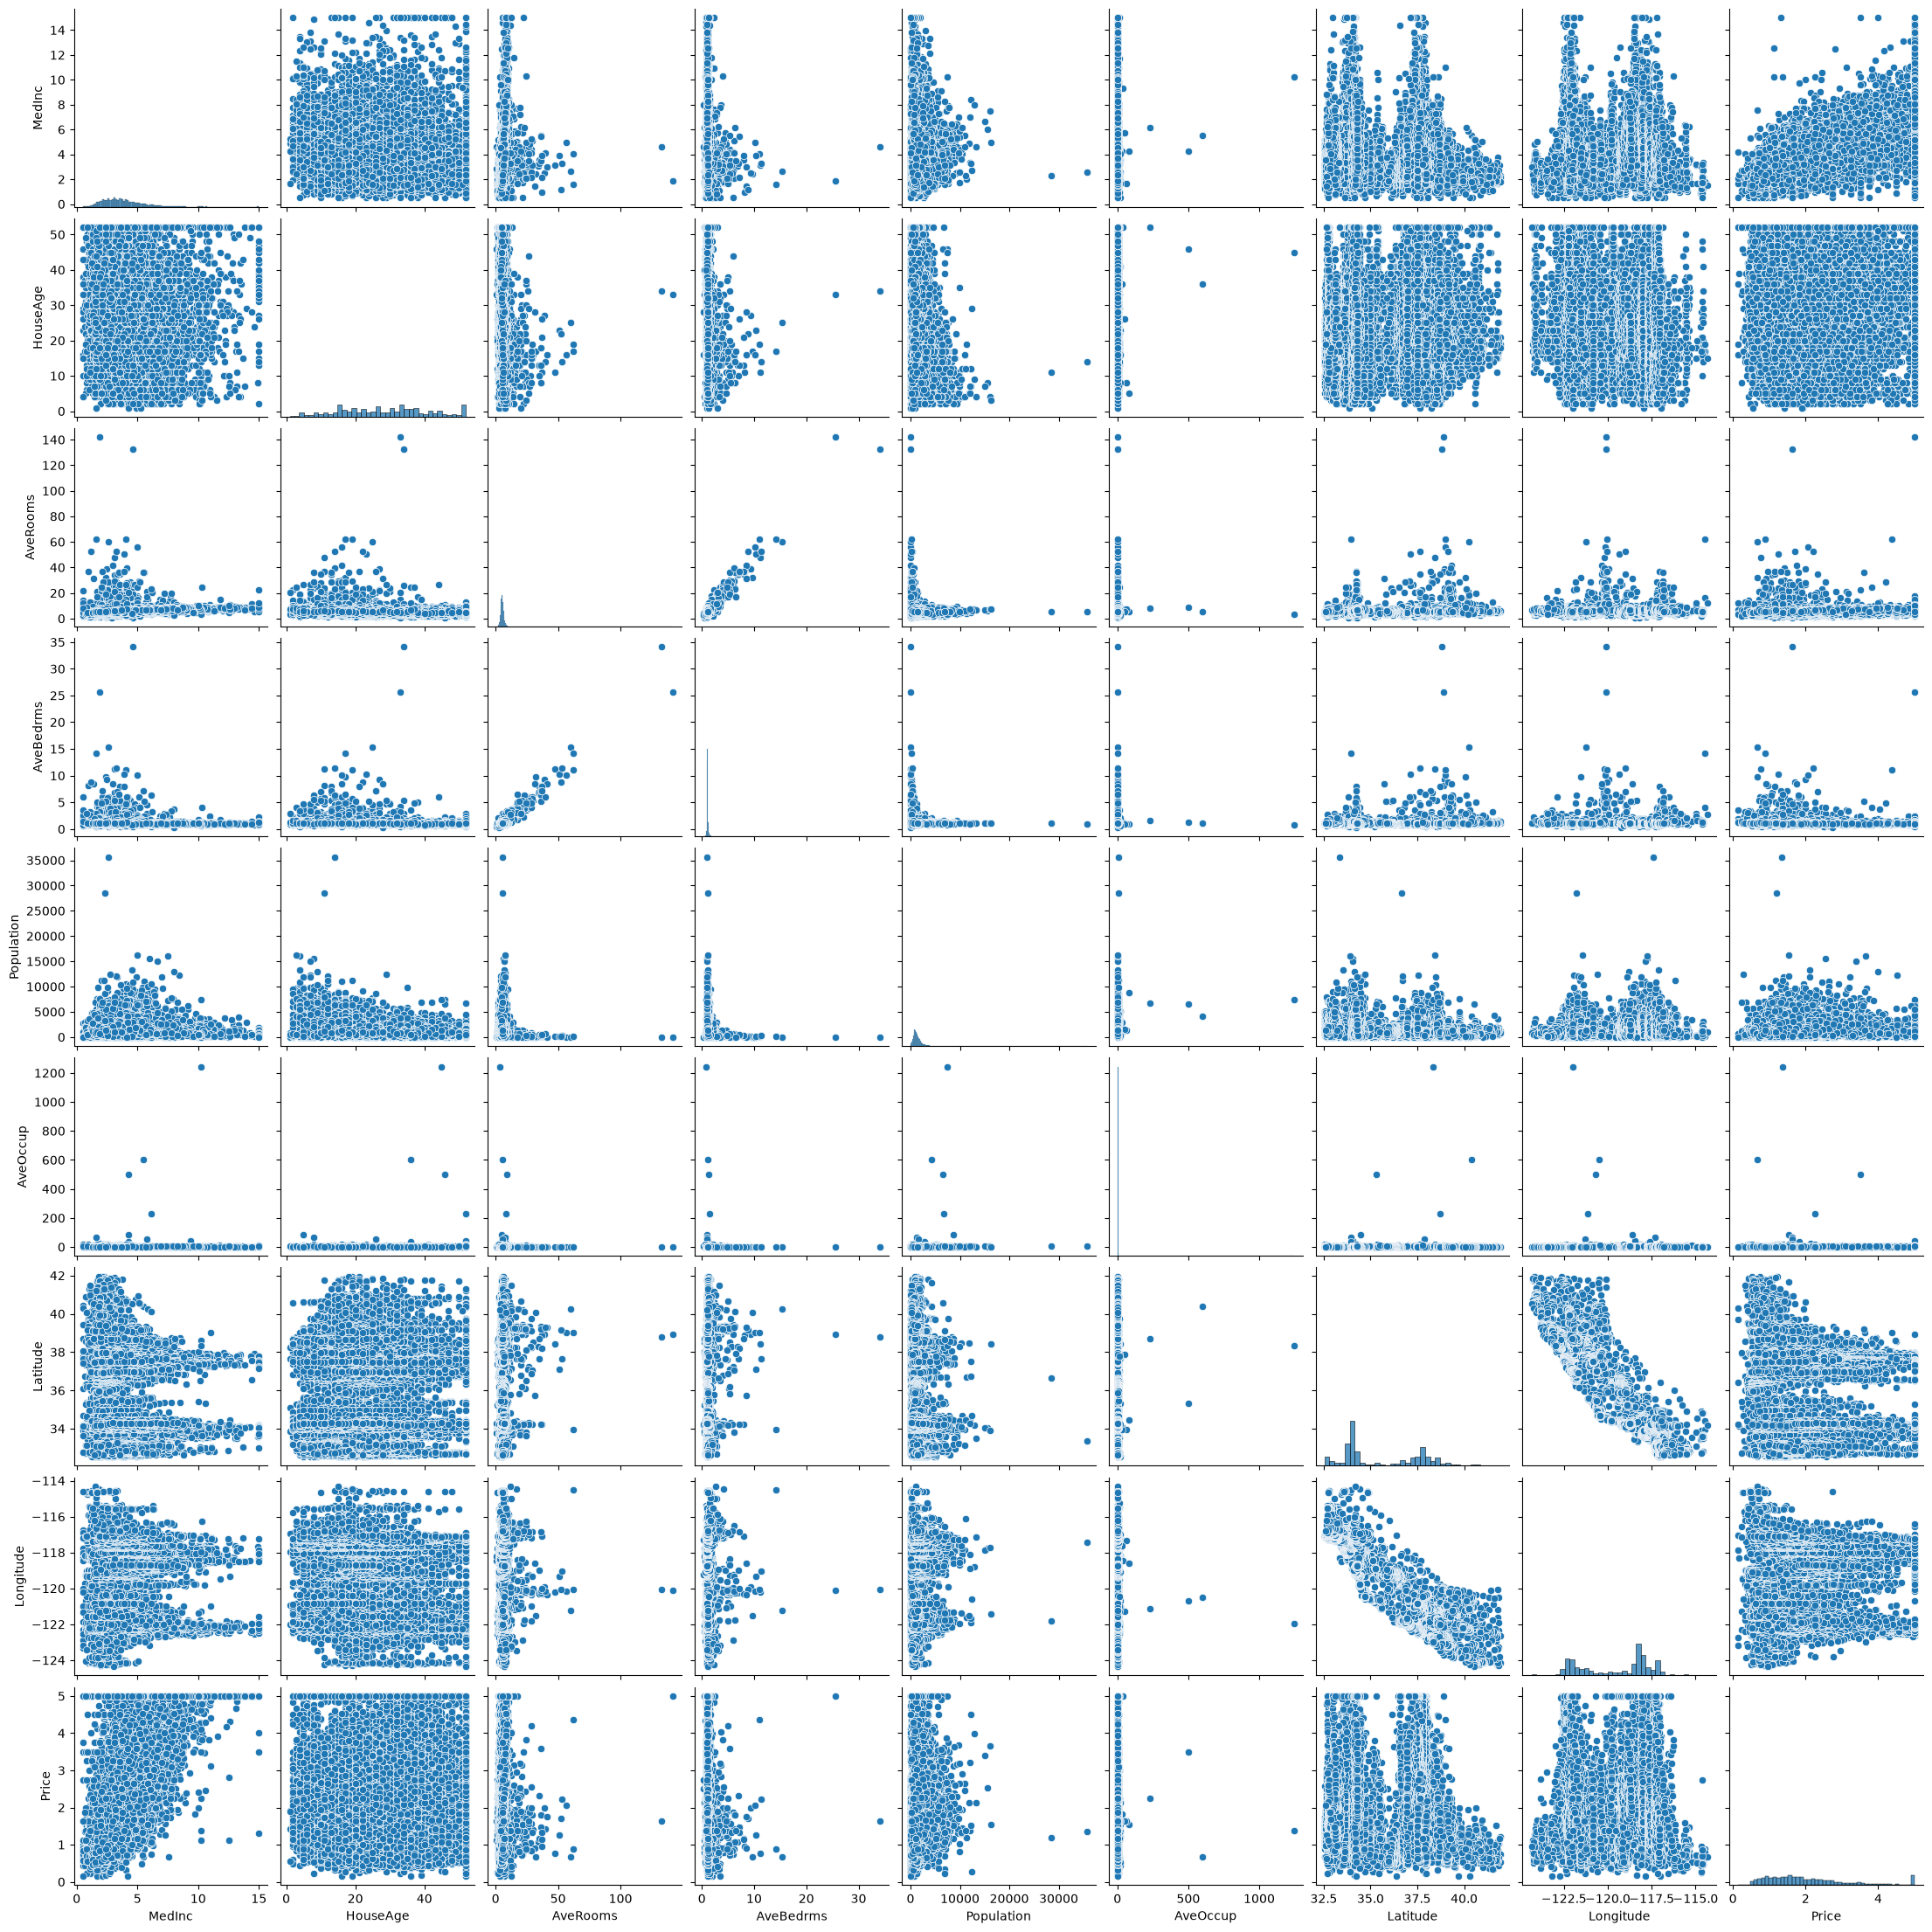

In [313]:
import numpy as np

#pairplot
data = pd.DataFrame(data)
sns.pairplot(data)

In [314]:
# AveRooms and AveBedrms are highly correlated, we will drop AveBedrms
if "AveBedrms" in data.columns:
    data = data.drop(columns = ["AveBedrms"])

The pairplot shows the outliers very clearly. Let's remove some of the outliers...

In [315]:
def look_for_outliers(df, column, remove_outliers=False):
    # Print basic statistics of the specified column
    print(df[column].describe())
    
    # Print the five highest values of the specified column
    print(f"Printing the five highest values of {column}:")
    print(df[column].nlargest(5))
    
    # Print all the rows where the specified column is greater than its 95th percentile
    print(f"Printing all rows where {column} is greater than its 95th percentile:")
    threshold = df[column].quantile(0.95)
    print(df[df[column] > threshold].sort_values(by=column, ascending=False))

    if remove_outliers:
        # Remove outliers from the specified column
        df = df[df[column] <= threshold]
    
    return df

## Trimming Values and Columns

In [316]:
trimming_outliers = True  # Set to True if you want to remove outliers
if trimming_outliers:
    # Let's trim the some columns a little more aggressively. 
    data = data[data['AveRooms'] <= 20]
    data = data[data['AveOccup'] <= 10]
    data = data[data['Population'] <= 15000]
    data = data[data['Price'] < 5.0]
    data = data[data['HouseAge'] < 52]

In [317]:
columns_to_drop = [
    "Latitude", 
    "Longitude", 
    "HouseAge", 
    "Population", 
    #"AveBedrms"
]

removing_columns = True  # Set to True if you want to remove specified columns
if removing_columns:
    for column in columns_to_drop:
        if column in data.columns:
            data = data.drop(columns=[column])

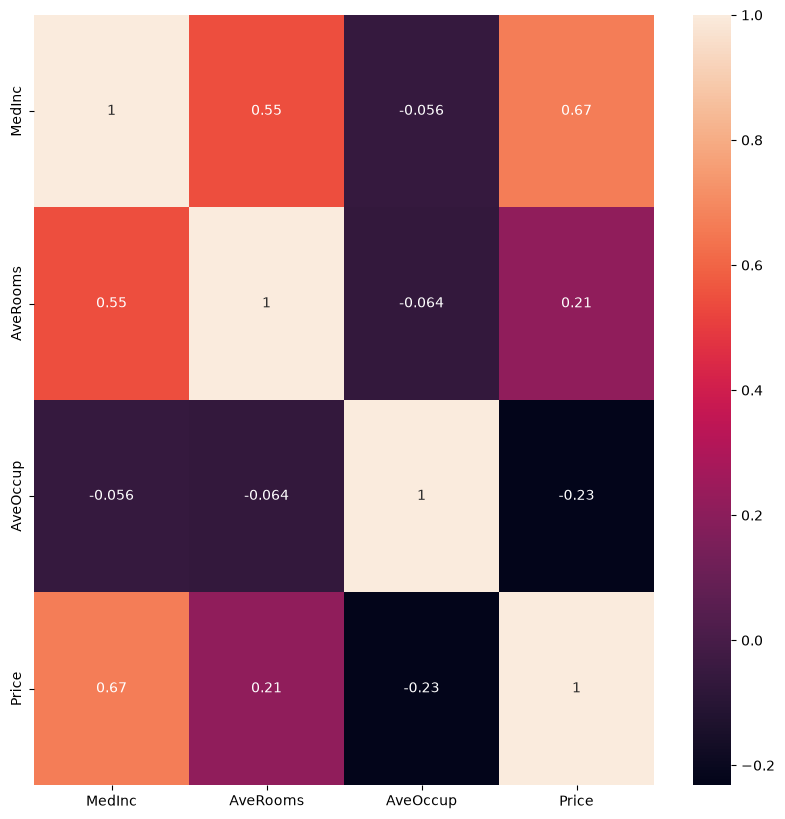

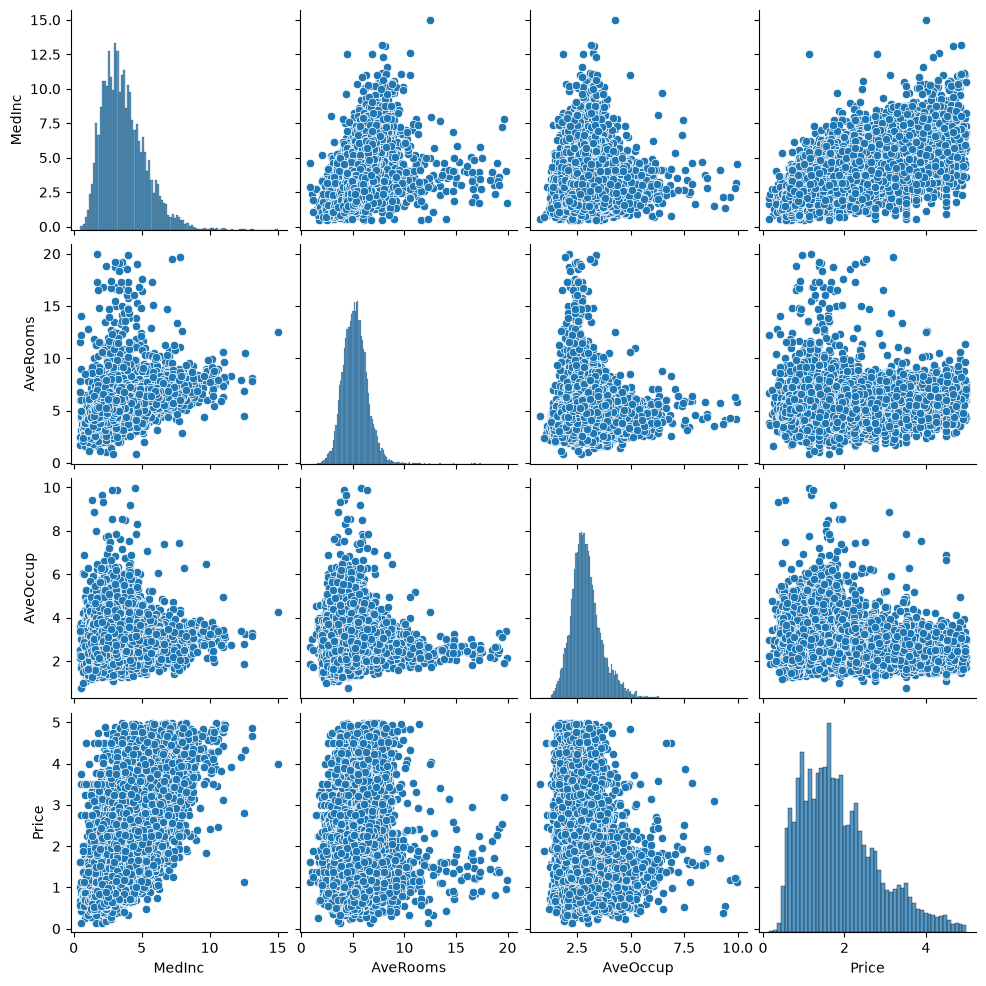

In [318]:
plt.figure(figsize = (10, 10))
sns.heatmap(data.corr(), annot = True)
sns.pairplot(data)

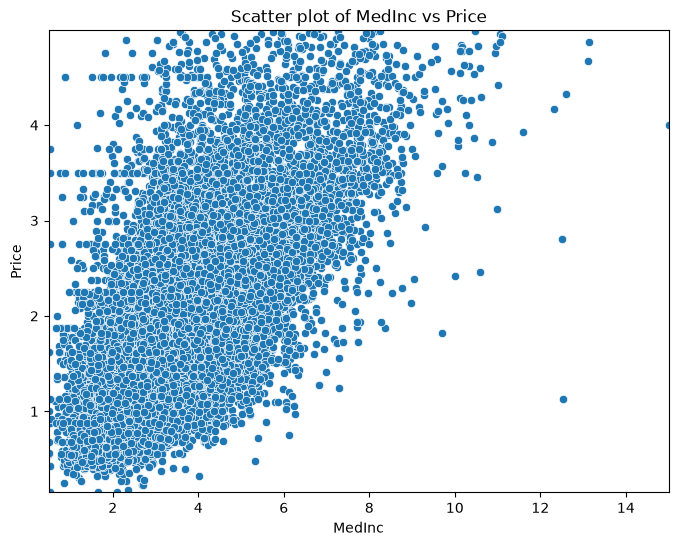

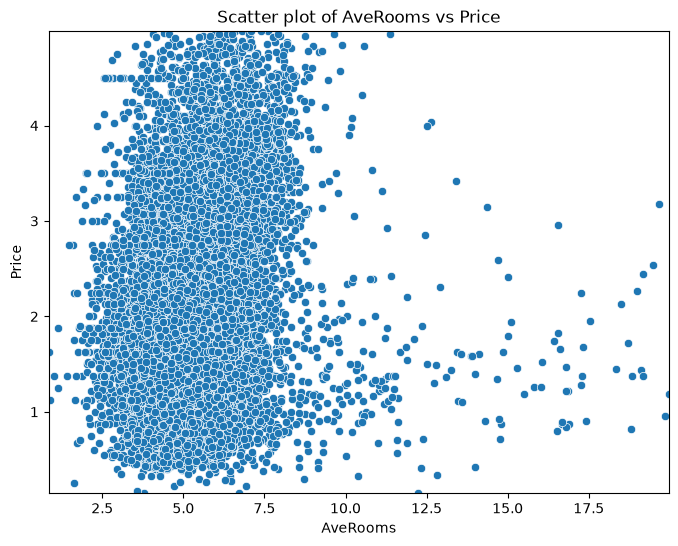

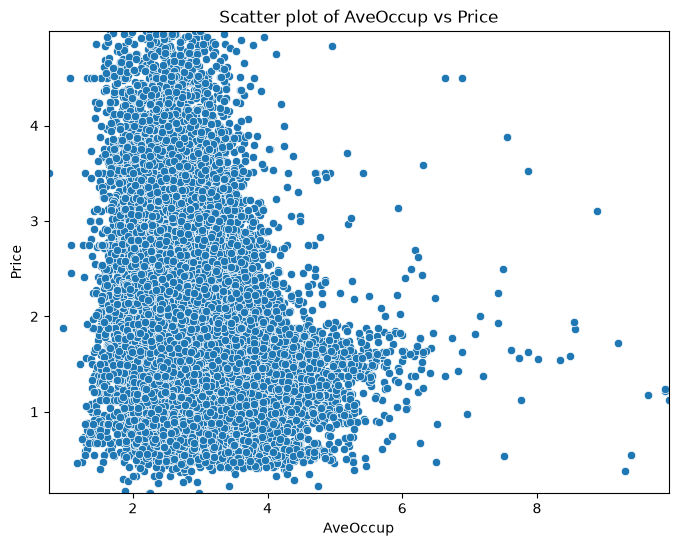

In [319]:
# Let's look at scatterplots of each of the features against the target variable to 
# see if there are any obvious relationships.

for column in data.columns:
    if column != 'Price':
        plt.figure(figsize=(8, 6))
        sns.scatterplot(x=data[column], y=data['Price'])
        plt.title(f'Scatter plot of {column} vs Price')
        plt.xlabel(column)
        plt.ylabel('Price')
        plt.xlim(data[column].min(), data[column].max())
        plt.ylim(data['Price'].min(), data['Price'].max())
        plt.show()

## Data Splitting and Scaling

In [320]:
from sklearn.model_selection import train_test_split

def split_data(data: pd.DataFrame, test_size=0.2) -> dict:
    """
    Splits the data into training and testing sets.

    Parameters:
    - data: pd.DataFrame - The input data containing features and target.
    - test_size: float - The proportion of the dataset to include in the test split.

    Returns:
    - dict: A dictionary containing the split datasets.
    """
    # Identify features and target
    features = data.columns[0:-1]
    target = data.columns[-1]

    # Extract X and y values
    X = data[features].values
    y = data[target].values

    # Split the dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=17)

    return {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }

In [321]:
from sklearn.linear_model import LinearRegression, Ridge

model_data = split_data(data)
X_train = model_data["X_train"]
X_test = model_data["X_test"]
y_train = model_data["y_train"]
y_test = model_data["y_test"]

#Model
lr = LinearRegression()

#Fit model
lr.fit(X_train, y_train)

train_score_lr = lr.score(X_train, y_train)
test_score_lr = lr.score(X_test, y_test)

print("The train score for lr model is {}".format(train_score_lr))
print("The test score for lr model is {}".format(test_score_lr))


#Ridge Regression Model
ridgeReg = Ridge(alpha=10)

ridgeReg.fit(X_train,y_train)

#train and test scorefor ridge regression
train_score_ridge = ridgeReg.score(X_train, y_train)
test_score_ridge = ridgeReg.score(X_test, y_test)

print("\nRidge Model............................................\n")
print("The train score for ridge model is {}".format(train_score_ridge))
print("The test score for ridge model is {}".format(test_score_ridge))


The train score for lr model is 0.520369565108836
The test score for lr model is 0.5027291046128596

Ridge Model............................................

The train score for ridge model is 0.5203694080940199
The test score for ridge model is 0.502736751085811


In [322]:
# Run the Ridge regression with different alpha values to see how it affects the model's performance.
for i in range(-5, 5):
    alpha = 10 ** i
    ridgeReg = Ridge(alpha=alpha)
    ridgeReg.fit(X_train, y_train)
    train_score_ridge = ridgeReg.score(X_train, y_train)
    test_score_ridge = ridgeReg.score(X_test, y_test)
    print(f"Alpha: {alpha:.2e}, Train Score: {train_score_ridge:.4f}, Test Score: {test_score_ridge:.4f}")

Alpha: 1.00e-05, Train Score: 0.5204, Test Score: 0.5027
Alpha: 1.00e-04, Train Score: 0.5204, Test Score: 0.5027
Alpha: 1.00e-03, Train Score: 0.5204, Test Score: 0.5027
Alpha: 1.00e-02, Train Score: 0.5204, Test Score: 0.5027
Alpha: 1.00e-01, Train Score: 0.5204, Test Score: 0.5027
Alpha: 1.00e+00, Train Score: 0.5204, Test Score: 0.5027
Alpha: 1.00e+01, Train Score: 0.5204, Test Score: 0.5027
Alpha: 1.00e+02, Train Score: 0.5204, Test Score: 0.5028
Alpha: 1.00e+03, Train Score: 0.5190, Test Score: 0.5020
Alpha: 1.00e+04, Train Score: 0.4700, Test Score: 0.4553


In [323]:
# Print the details of ridgeReg
print("\nRidge Model Details............................................\n")
print(f"Ridge Regression Coefficients: {ridgeReg.coef_}")
print(f"Ridge Regression Intercept: {ridgeReg.intercept_}")

# Print the number of features used in the Ridge regression model
num_features = len(ridgeReg.coef_)
print(f"Number of features used in Ridge regression: {num_features}")



Ridge Model Details............................................

Ridge Regression Coefficients: [ 0.33503954 -0.04506063 -0.11815541]
Ridge Regression Intercept: 1.2462569737471303
Number of features used in Ridge regression: 3


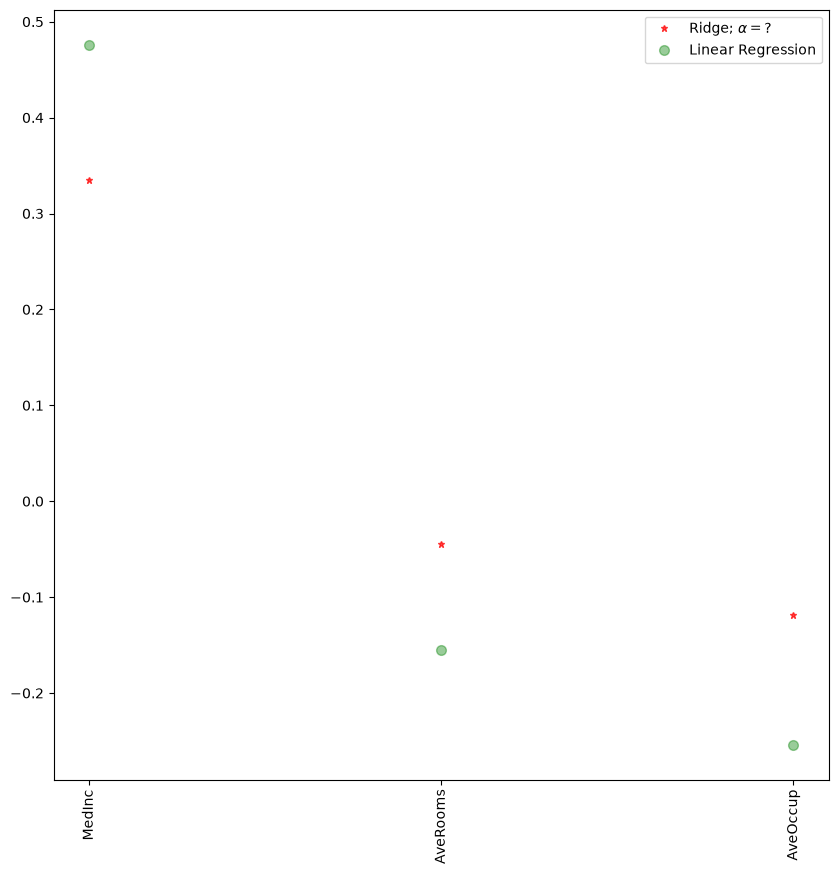

In [324]:
plt.figure(figsize = (10, 10))
features = data.columns[0:-1]
plt.plot(features,ridgeReg.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Ridge; $\alpha = ?$',zorder=7)
#plt.plot(rr100.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Ridge; $\alpha = 100$')
plt.plot(features,lr.coef_,alpha=0.4,linestyle='none',marker='o',markersize=7,color='green',label='Linear Regression')
plt.xticks(rotation = 90)
plt.legend()
plt.show()


In [325]:
#Lasso regression model
from sklearn.linear_model import Lasso

print("\nLasso Model............................................\n")
lasso = Lasso(alpha = 0.01)
lasso.fit(X_train,y_train)
train_score_ls =lasso.score(X_train,y_train)
test_score_ls =lasso.score(X_test,y_test)

print("The train score for ls model is {}".format(train_score_ls))
print("The test score for ls model is {}".format(test_score_ls))



Lasso Model............................................

The train score for ls model is 0.5199466624596276
The test score for ls model is 0.5024247252233434


<Axes: >

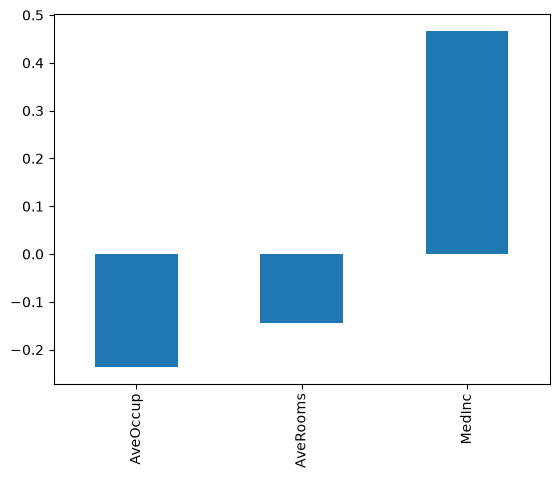

In [326]:
pd.Series(lasso.coef_, features).sort_values(ascending = True).plot(kind = "bar")

In [327]:
print(f"Number of features used in Lasso Regression: {np.sum(lasso.coef_ != 0)}")
print(f"Lasso Regression Coefficients:\n{pd.Series(lasso.coef_, features)}")

Number of features used in Lasso Regression: 3
Lasso Regression Coefficients:
MedInc      0.466804
AveRooms   -0.143356
AveOccup   -0.236115
dtype: float64


In [328]:
#Using the linear CV model
from sklearn.linear_model import LassoCV

#Lasso Cross validation
lasso_cv = LassoCV(alphas = 100, random_state=0).fit(X_train, y_train)


#score
print(lasso_cv.score(X_train, y_train))
print(lasso_cv.score(X_test, y_test))


0.520365261805039
0.5027406059599724


In [329]:
#Using the Ridge CV model
from sklearn.linear_model import RidgeCV

#Ridge Cross validation
alpha_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10])
ridge_cv = RidgeCV(alphas = alpha_values).fit(X_train, y_train)

#score
print("The train score for ridge model is {}".format(ridge_cv.score(X_train, y_train)))
print("The train score for ridge model is {}".format(ridge_cv.score(X_test, y_test)))

The train score for ridge model is 0.5203694080940199
The train score for ridge model is 0.502736751085811


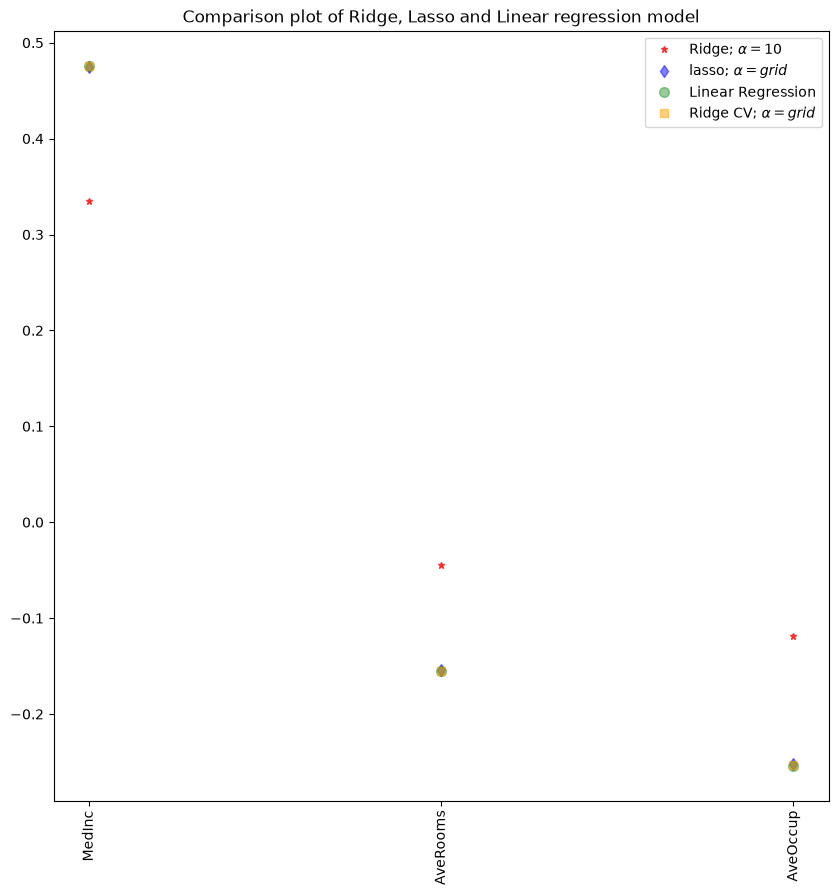

In [330]:
#plot size
plt.figure(figsize = (10, 10))
#add plot for ridge regression
plt.plot(features,ridgeReg.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Ridge; $\alpha = 10$',zorder=7)

#add plot for lasso regression
plt.plot(lasso_cv.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'lasso; $\alpha = grid$')

#add plot for linear model
plt.plot(features,lr.coef_,alpha=0.4,linestyle='none',marker='o',markersize=7,color='green',label='Linear Regression')

#add plot for ridge cv regression
plt.plot(ridge_cv.coef_,alpha=0.5,linestyle='none',marker='s',markersize=6,color='orange',label=r'Ridge CV; $\alpha = grid$')

#rotate axis
plt.xticks(rotation = 90)
plt.legend()
plt.title("Comparison plot of Ridge, Lasso and Linear regression model")
plt.show()
